In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
air=pd.read_csv('City_Air_Quality.csv')
air=air[air['City']=='Delhi'].copy()
air.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [38]:
air['Date']=pd.to_datetime(air['Date'])
air=air.set_index('Date')

In [40]:
relevant=['PM2.5','PM10','CO','AQI','AQI_Bucket']

In [42]:
air[relevant].info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2009 entries, 2015-01-01 to 2020-07-01
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   PM2.5       2007 non-null   float64
 1   PM10        1932 non-null   float64
 2   CO          2009 non-null   float64
 3   AQI         1999 non-null   float64
 4   AQI_Bucket  1999 non-null   object 
dtypes: float64(4), object(1)
memory usage: 94.2+ KB


In [44]:
air[relevant].isna().sum()
air.head()

,City,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
Date,,,,,,,,,,,,,,,
2015-01-01,Delhi,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
2015-01-02,Delhi,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
2015-01-03,Delhi,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
2015-01-04,Delhi,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
2015-01-05,Delhi,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


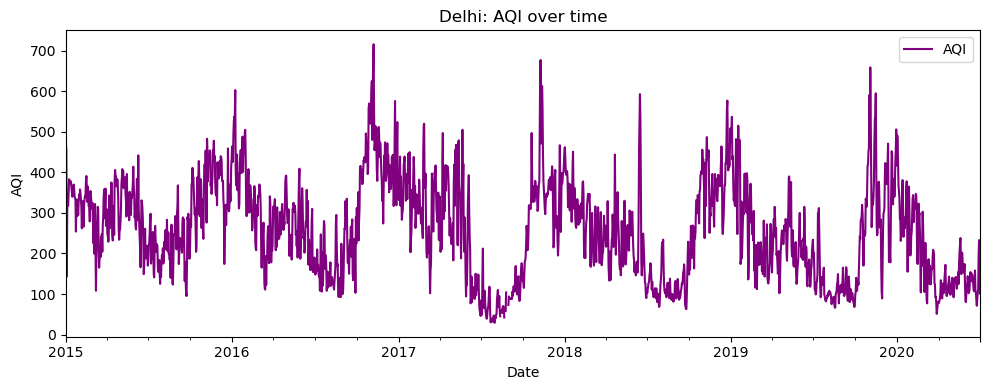

In [46]:
# Plot the overall daily AQI trend.
air['AQI'].plot(figsize=(10, 4), color='purple', label='AQI')
plt.title('Delhi: AQI over time')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.legend()
plt.tight_layout()
plt.show()

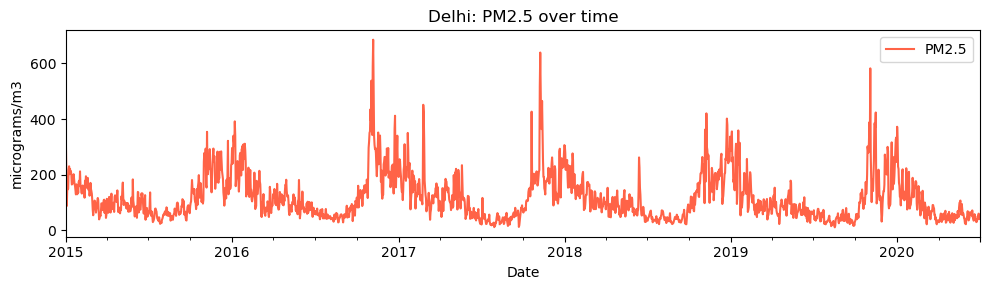

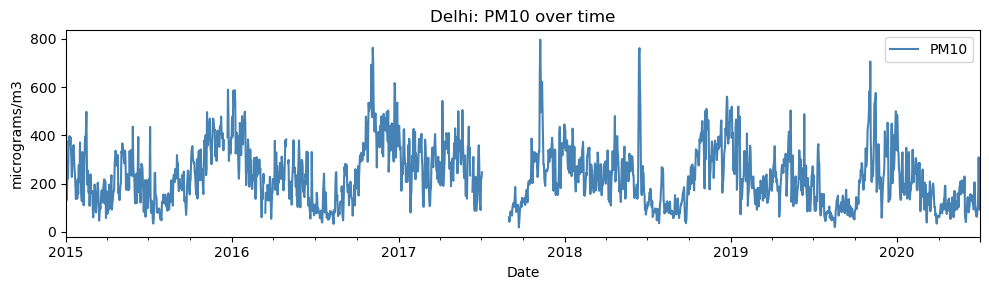

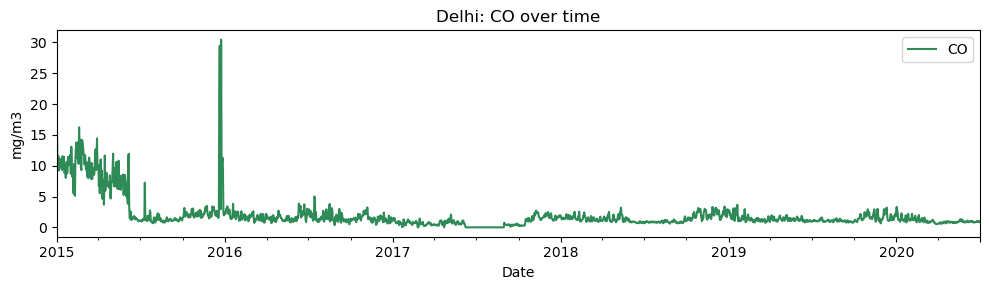

In [48]:
# Plot each pollutant separately so their units remain clear.
for pollutant, unit, color in [('PM2.5', 'micrograms/m3', 'tomato'),
                                ('PM10', 'micrograms/m3', 'steelblue'),
                                ('CO', 'mg/m3', 'seagreen')]:
    air[pollutant].plot(figsize=(10, 3), color=color, label=pollutant)
    plt.title(f'Delhi: {pollutant} over time')
    plt.xlabel('Date')
    plt.ylabel(unit)
    plt.legend()
    plt.tight_layout()
    plt.show()

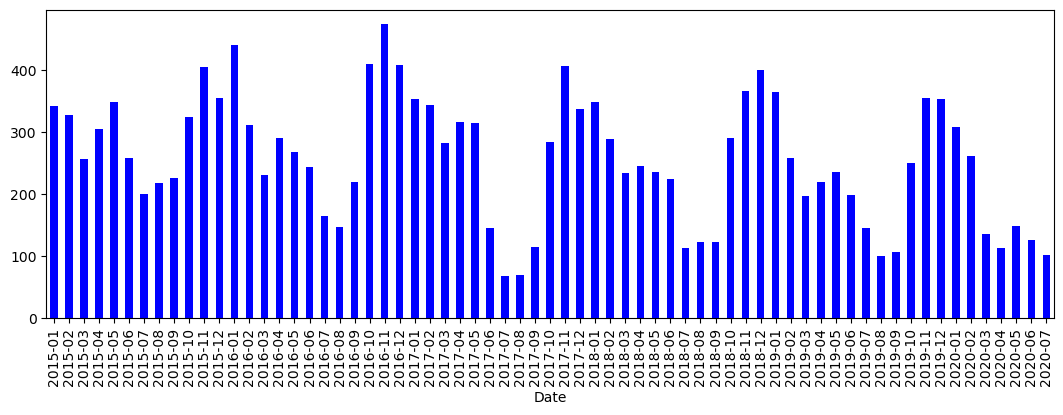

In [49]:
#compare AQI across months using the bar chart
monthly_aqi=air['AQI'].resample('ME').mean()
monthly_aqi.index=monthly_aqi.index.strftime('%Y-%m')
monthly_aqi.plot(kind='bar',figsize=(13,4),color='blue')
plt.show()

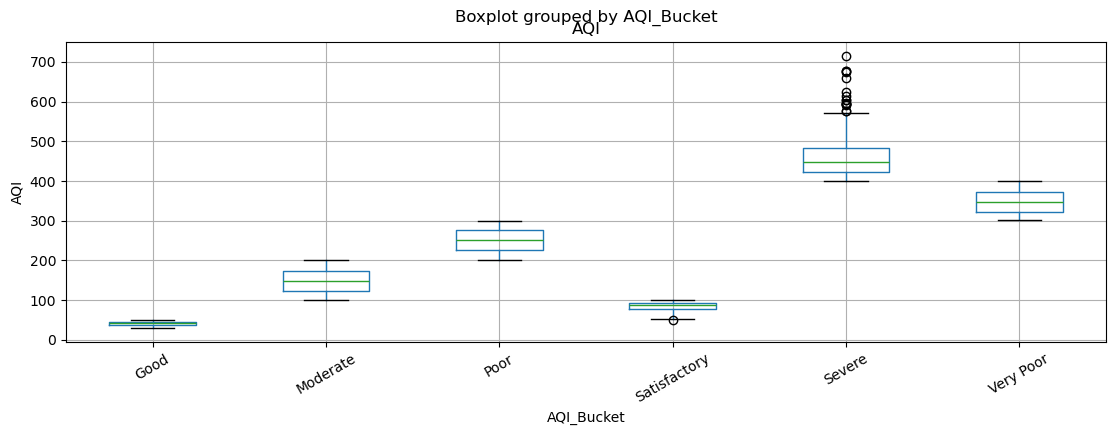

In [57]:
#compare aqi distributions across the datasets air-quality categories
air.dropna(subset=['AQI','AQI_Bucket']).boxplot(column='AQI',by='AQI_Bucket',rot=30 , figsize=(13,4))
plt.ylabel('AQI')
plt.show()

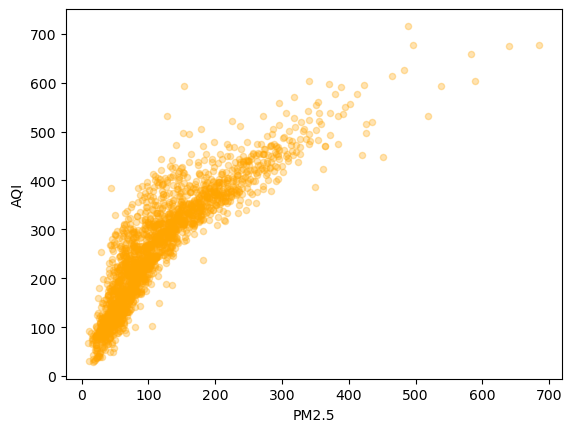

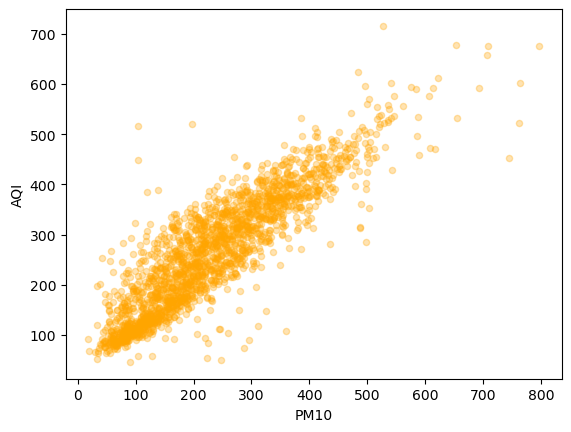

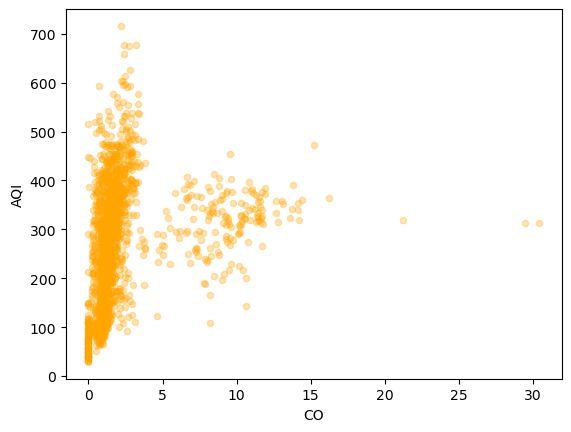

In [59]:
#show how aqi relates to the individual pollutant levels
for pollutant in['PM2.5','PM10','CO']:
    air.plot.scatter(x=pollutant,y='AQI',alpha=0.3 , color='orange')